# 5. Custom reference

This tutorial builds a cell-type reference from a labeled single-cell atlas and uses it to annotate
previously encoded H&E cells.

> **This tutorial teaches**
>
> - **Task:** build and use a custom single-cell reference
> - **Required inputs:** a single-cell atlas with raw counts and one label per cell, together with
>   previously computed `CellEmbeddings`
> - **Outputs:** a reference file and an `AnnotationResult` using the custom taxonomy
> - **Example used here:** an `.h5ad` atlas and the cells saved in Tutorial 2
> - **Key concept:** projecting a labeled atlas into ALHENA's shared cell space

Building a reference has two steps. First, embed the single-cell atlas with the dedicated atlas
environment. Then use ALHENA to project those embeddings into the shared cell space and build the
reference file.

> **Example outputs.** The outputs shown in this tutorial come from the DISCO breast atlas, 174,638
> cells of adjacent-normal and control breast tissue, each labeled with one of four classes. The H&E
> cells are those of Tutorial 2.
>
> Source: [DISCO](https://www.immunesinglecell.org/), presented in
> [Li et al. (Nucleic Acids Res, 2022)](https://doi.org/10.1093/nar/gkab1020). DISCO states: "All data
> and scripts in DISCO are free for academic research."

## Step 1: embed the atlas

The atlas-embedding dependencies differ from the main ALHENA environment, so this step is run from
a clone of the repository using the provided `alhena_atlas` environment:

```bash
git clone https://github.com/prism-oncology/ALHENA.git
cd ALHENA
python3.12 -m venv alhena_atlas
source alhena_atlas/bin/activate
pip install -r scripts/requirements-atlas.txt
python -c "from concept import scConcept; scConcept(cache_dir='$HOME/.cache/sc-concept').load_config_and_model(model_name='corpus40M-model30M')"
python scripts/alhena_atlas_embed.py \
    --atlas breast_atlas.h5ad \
    --output breast_cls_emb.h5
```

The provided atlas-embedding script uses
[scConcept](https://github.com/theislab/scConcept) to generate one 512-dimensional embedding for
each atlas cell. The input `.h5ad` must contain the raw counts of the atlas, and the script
preserves atlas row order in the output. The `python -c` line downloads the scConcept model
files once, into `~/.cache/sc-concept`, where the script reads them.

**Keep the atlas row order unchanged between embedding and reference construction.** Labels are
associated with embeddings by row position.

If raw counts are stored in a layer rather than `X`, provide that layer explicitly:

```bash
python scripts/alhena_atlas_embed.py \
    --atlas breast_atlas.h5ad \
    --output breast_cls_emb.h5 \
    --layer counts
```

See [Embed the atlas](../../concepts/references/#step-1-embed-the-single-cell-atlas) for the
available options.

## Step 2: build the reference

The remaining steps run in the standard ALHENA environment. Configure the atlas embeddings,
labels, taxonomy, and output file below.

The reference and its self-check use ALHENA's retrieval operator. By default, `k=30` is the number
of reference neighbors retained for each query, and `tau=0.03` is the softmax temperature used
when their similarities are converted into voting weights. These values are printed in the setup
cell below. See
[Retrieval operator](../../concepts/cell-typing/#retrieval-operator) for details.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import alhena

# Optional model configuration, as in Tutorial 1.
BACKBONE = None
BUNDLE = None
DEVICE = None

# Written by Step 1, in the row order of the atlas.
EMBEDDINGS = Path("breast_cls_emb.h5")

# One label per cell, in that same order. An array, a table, or the path of a .csv, .tsv or
# .parquet file holding one.
LABELS = Path("breast_labels.csv")
LABEL_COLUMN = "cell_type"

# Reference file to create.
SHARD = Path("breast_own.safetensors")

# Custom taxonomy and class order.
AXIS = "my_taxonomy_v1"
CLASS_ORDER = ("Epithelial", "Stroma", "Immune", "Endothelium")

# The cells Tutorial 2 saved, encoded before this reference existed.
CELLS = Path("alhena_out/cells.h5ad")

print(alhena.__version__)
print("declared axes:", sorted(alhena.CLASS_AXES))
print("operator: k =", alhena.DEFAULT_K, " tau =", alhena.DEFAULT_TAU)

0.1.0
declared axes: ['compartment_v1', 'lineage_v1']
operator: k = 30  tau = 0.03


## Inspect the atlas embeddings and labels

Before building the reference, load the encoder, atlas embeddings, and labels and verify that their
dimensions and row counts are compatible. The code below does **not** project the atlas embeddings
yet; that projection is performed by `build_reference()` in the next section.

Compatibility with H&E-derived cells is identified by `cell_space_id`, not by dimensionality
alone. Two incompatible releases may both use 512-dimensional vectors. See
[Reference compatibility](../../concepts/references/#reference-compatibility).

The labels must remain in exactly the same row order as the atlas embeddings generated in Step 1.

In [2]:
encoder = alhena.load_encoder(backbone=BACKBONE, bundle=BUNDLE, device=DEVICE)

matrix = alhena.read_scconcept_embeddings(EMBEDDINGS)
print("atlas embeddings", matrix.shape, matrix.dtype)
print("the reference head reads", matrix.shape[1], "and writes", encoder.info.cell_dim)

labels = pd.read_csv(LABELS)[LABEL_COLUMN]
print("labels", len(labels), "against", matrix.shape[0], "cells")

seen = {str(value).strip() for value in labels.dropna()}
print("label values matching no class:", sorted(seen - set(CLASS_ORDER)))

atlas embeddings (174638, 512) float32
the reference head reads 512 and writes 512
labels 174638 against 174638 cells
label values matching no class: []


## Define the taxonomy and build the reference

`build_reference()` applies ALHENA's learned reference projection to the atlas embeddings, writes
the completed reference file, and runs the reference self-check.

`class_order` defines the classes available to the reference and fixes their internal order.

- Use a distinct `axis` name for a custom taxonomy. The built-in `lineage_v1` and
  `compartment_v1` axes have fixed class definitions.
- Each labeled atlas cell must map to one of the classes in `class_order`.
- Values explicitly listed through `unlabeled` are excluded from the retrieval pool rather than
  treated as classes.

The custom reference keeps the same ALHENA retrieval defaults introduced above. A custom axis
therefore raises an `EnvelopeWarning` to indicate that these retrieval settings were not selected
on this taxonomy.

See [What a build guarantees](../../concepts/references/#what-a-build-guarantees-and-what-it-does-not).

In [3]:
with warnings.catch_warnings(record=True) as raised:
    warnings.simplefilter("always")
    report = alhena.build_reference(
        EMBEDDINGS,
        LABELS,
        encoder,
        SHARD,
        name="breast_own",
        axis=AXIS,
        class_order=CLASS_ORDER,
        label_column=LABEL_COLUMN,
        source="DISCO breast atlas (https://www.immunesinglecell.org/)",
        license="Free for academic research, as stated by DISCO.",
    )

print("wrote", report.path)
print("rows", report.n_rows, " labeled", report.n_labeled[AXIS])
print("unusable projections", report.n_invalid_embeddings)
print("class order", report.class_orders[AXIS])

for entry in raised:
    print(type(entry.message).__name__, entry.message)

wrote breast_own.safetensors
rows 174638  labeled 174638
unusable projections 0
class order ('Epithelial', 'Stroma', 'Immune', 'Endothelium')
EnvelopeWarning Axis 'my_taxonomy_v1' carries 4 classes, so k over classes is 7.50 at k=30. The operator k=30, tau=0.03 was selected on a pool of atlases, on a five-class and a three-class axis, and is not tuned on this taxonomy.


## Inspect class support

The build report records how many reference cells support each class.

A class with no reference cells cannot be predicted. Classes with relatively little support are
reported separately because they contribute fewer candidate neighbors to the retrieval pool.

`report.info.missing_classes` and `report.info.thin_classes` expose these conditions
programmatically. See
[Reference coverage and retrieval warnings](../../concepts/references/#reference-coverage-and-retrieval-warnings).

In [4]:
info = report.info
print("rows in the reference", info.n_cells, " in the retrieval pool", info.n_scored_cells)

for class_name, count in info.class_support.items():
    if count == 0:
        mark = "no reference cells"
    elif class_name in info.thin_classes:
        mark = "thinly supported"
    else:
        mark = ""
    print(f"  {class_name:<24} {count:>8}  {mark}")

rows in the reference 174638  in the retrieval pool 174638
  Epithelial                 118027  
  Stroma                      31599  
  Immune                       7451  
  Endothelium                 17561  


## Validate the reference with the self-check

`build_reference()` has already run this check and stored the result in `report.self_check`; the
code below only inspects that result.

The self-check asks a simple question: for each atlas cell used as a query, can the reference
recover that cell's atlas label from other reference cells when the query cell itself is excluded
from its neighbors?

Poor recovery indicates that the projected reference and chosen taxonomy do not separate the atlas
labels well under the retrieval operator. The reported macro F1, accuracy, per-class recall, and
similarity summaries describe this reference-to-reference check.

Successful self-retrieval shows internal consistency of the reference, but it does **not**
establish annotation accuracy on H&E-derived cells. Deployment compares image-derived
representations with reference cells, which is a different evaluation problem.

In [5]:
check = report.self_check
print("axis", check.axis, " at k =", check.k, " tau =", check.tau)

# Large references may evaluate the self-check on a reproducible query subsample.
print("cells scored", check.n_cells_evaluated, "of", report.n_rows)

print("macro F1", round(check.macro_f1, 4), " accuracy", round(check.accuracy, 4))
print("recall per class")
for class_name, recall in check.per_class_recall.items():
    print(f"  {class_name:<24} {recall:.4f}")
for note in check.warnings:
    print(note)

axis my_taxonomy_v1  at k = 30  tau = 0.03
cells scored 174638 of 174638
macro F1 0.9986  accuracy 0.9993
recall per class
  Epithelial               0.9999
  Stroma                   0.9972
  Immune                   0.9989
  Endothelium              0.9987


## Load the completed reference

`load_reference()` loads the custom reference and restores its taxonomy, class order, provenance,
and shared-cell-space identity.

In [6]:
reference = alhena.load_reference(path=SHARD, axis=AXIS)

print(reference.info.name, reference.info.axis)
print("source", reference.info.source)
print("license", reference.info.license)

breast_own my_taxonomy_v1
source user-built: DISCO breast atlas (https://www.immunesinglecell.org/)
license Free for academic research, as stated by DISCO.


## Annotate previously encoded cells

A custom reference can annotate `CellEmbeddings` exactly as a prebuilt reference does.

Because cell encoding is independent of the reference, the cells saved in Tutorial 2 do not need
to be recomputed. `CellTyper` verifies that their `cell_space_id` matches the reference before
annotation.

This workflow therefore loads the saved cells and performs retrieval directly in the shared cell
space. See [Annotating cells again](../../concepts/cell-typing/#annotating-cells-again).

In [7]:
typer = alhena.load_celltyper(reference=reference)
cells = alhena.io.read_cells(CELLS)
result = typer.annotate(cells)
frame = result.to_frame()

print("encoder loaded:", typer.encoder is not None)
print(len(result), "cells,", int(result.valid.sum()), "annotated on", result.axis)
print(frame["label"].value_counts())
frame[["cell_id", "label", "confidence", "valid"]].head()

encoder loaded: False
36804 cells, 36804 annotated on my_taxonomy_v1
label
Epithelial     21856
Stroma         11818
Immune          1673
Endothelium     1457
Name: count, dtype: int64


,cell_id,label,confidence,valid
0,ablknega-1,Epithelial,1.0,True
1,abllcdad-1,Epithelial,1.0,True
2,ablljpoe-1,Epithelial,1.0,True
3,abllmagm-1,Epithelial,1.0,True
4,abllobgk-1,Epithelial,1.0,True


## Visualize the custom annotation

The custom reference has four classes. Its predicted class composition can be visualized in the
same way as the prebuilt-reference results in Tutorial 3.

Custom class names need explicit plotting colors. `composition()` and `legend()` use the same colors
and class order, keeping the visualization consistent with the new taxonomy.

The figure summarizes **predicted classes**, not the results of an independent accuracy evaluation.

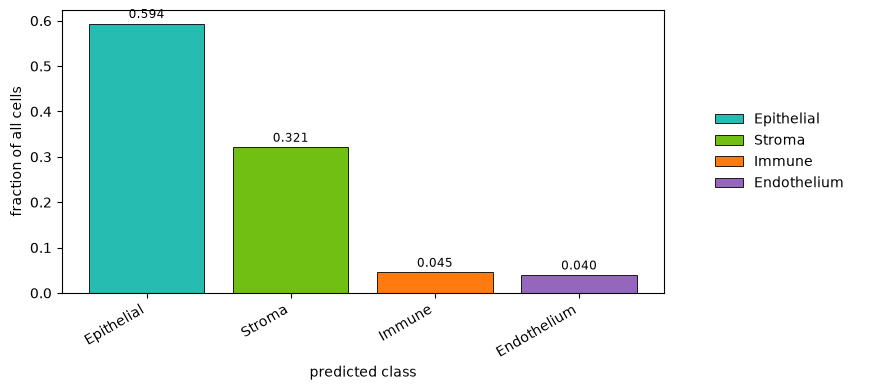

In [8]:
import matplotlib.pyplot as plt

from alhena import viz

colors = {
    "Epithelial": alhena.CLASS_COLORS["Epithelial_Melanocyte"],
    "Stroma": alhena.CLASS_COLORS["Stromal_Vascular"],
    "Immune": alhena.CLASS_COLORS["Immune"],
    "Endothelium": "tab:purple",
}

figure, axes = plt.subplots(1, 2, figsize=(9, 4), gridspec_kw={"width_ratios": [3, 1]})
viz.composition(result, ax=axes[0], colors=colors, show_no_call=False)
viz.legend(result.class_order, ax=axes[1], colors=colors, show_no_call=False)
figure.tight_layout()

## What this tutorial produced

The custom reference is now stored in `SHARD`, and the previously encoded cells have been
annotated using its taxonomy without rerunning the H&E encoder.

The same reference can be reused for new compatible cells. For new images, compute the cell
embeddings as usual and annotate them with this reference.

See [References](../../concepts/references/) for reference construction, compatibility, coverage,
and retrieval concepts.

---

**Next:** [6. Annotation evaluation](../06_annotation_evaluation/)